# Student Success Copilot
## A Hybrid AI System for Academic Planning and Risk Assessment

**Hybrid AI Systems — Coursework Notebook**

---

### System Overview
This notebook demonstrates a hybrid AI system integrating four components:
- **Component 1** — Search-Based Planner: Greedy Best-First vs A* Heuristic
- **Component 2** — Rule-Based Expert System: Forward + Backward Chaining (15 rules)
- **Component 3** — Machine Learning: RandomForest + LinearRegression
- **Component 4** — Fuzzy Logic Controller: Stress + Workload + Confidence → Intensity

### Notebook Structure
| Cell | Content |
|------|---------|
| Cell 1 | Mount Google Drive + setup |
| Cell 2 | Install dependencies |
| Cell 3 | Import all components |
| Cell 4 | Dataset overview |
| Cell 5 | ML training + evaluation + plots |
| Cell 6 | Rule engine demo (forward + backward chaining) |
| Cell 7 | Search planner demo (Greedy vs A*) |
| Cell 8 | Fuzzy logic demo |
| Cell 9 | Full system demo — two scenarios |
| Cell 10 | ML limitations discussion |

### How to Run
1. Run Cell 1 first — authorise Google Drive access
2. Run Cell 2 — installs scikit-learn 1.6.1
3. Run all remaining cells in order
**Or use Runtime → Run all**
```

---

## Step 2 — Rename the notebook

At the top of Colab click **Untitled0.ipynb** and rename it to:
```
student_success_copilot.ipynb
```

---

## Step 3 — Download the notebook

Go to **File → Download → Download .ipynb**

Save it to your PyCharm project folder alongside your `.py` files.

---

## Step 4 — Final submission checklist
```
✅ student_success_copilot.ipynb   ← Colab notebook
✅ planner/search_planner.py       ← Search component
✅ rules/rule_engine.py            ← Rule engine
✅ ml/ml_model.py                  ← ML inference
✅ ml/ml_training.py               ← ML training
✅ fuzzy/fuzzy_logic.py            ← Fuzzy logic
✅ ui/app.py                       ← Terminal UI
✅ main.py                         ← Entry point
✅ student_dataset.csv             ← Dataset
✅ model_risk.pkl                  ← Trained model
✅ model_label.pkl                 ← Trained model
✅ model_hours.pkl                 ← Trained model
✅ scaler.pkl                      ← Fitted scaler
✅ ssc_report_final.docx           ← Report
✅ prompts_log.zip                 ← Prompts file
```

---

## One last thing — create prompts_log.zip

Open Notepad and create a file called `prompts_log.txt`. Write your key prompts like this:
```
STUDENT SUCCESS COPILOT — AI ASSISTANCE PROMPTS LOG

1. " What will the project structure look like? Show me the folder structure I need to create?"
2. " How do I apply an 80/20 train-test split with stratification to keep balanced class distribution?"
3. "How do I train a RandomForestClassifier with scikit-learn on my student dataset?"
4. " How do I save and load scikit-learn models with joblib and so I can load them later?"
5. " How do I encode gender as a number for the ML model in the same way it was encoded during training?"
6. "How do I mount Google Drive in Colab and import .py files?"

In [61]:
# ── Cell 1: Mount Google Drive ──────────────────────────
from google.colab import drive
drive.mount('/content/drive')

import sys
import os

# Point Python to your project folder
PROJECT_PATH = '/content/drive/MyDrive/student_success_copilot'
sys.path.insert(0, PROJECT_PATH)

# Change working directory so pkl files are found correctly
os.chdir(PROJECT_PATH)

print("Drive mounted successfully!")
print(f"Project path: {PROJECT_PATH}")
print(f"Files found: {os.listdir(PROJECT_PATH)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted successfully!
Project path: /content/drive/MyDrive/student_success_copilot
Files found: ['main.py', 'student_dataset.csv', 'model_hours.pkl', 'model_risk.pkl', 'scaler.pkl', 'model_label.pkl', 'planner', 'rules', 'ml', 'fuzzy', 'ui', 'student_success_copilot.ipynb', 'model_evaluation.png']


In [62]:
# ── Cell 2: Install correct scikit-learn version ────────
!pip install scikit-learn==1.6.1 -q
print("scikit-learn 1.6.1 installed!")

scikit-learn 1.6.1 installed!


In [63]:
# ── Cell 3: Import all AI components ────────────────────
from planner.search_planner import build_tasks, greedy_planner, astar_planner
from rules.rule_engine import forward_chain, backward_chain, get_followup_question
from ml.ml_model import predict
from fuzzy.fuzzy_logic import fuzzy_controller

print("All components imported successfully!")
print("  ✓ Search Planner  (planner/search_planner.py)")
print("  ✓ Rule Engine     (rules/rule_engine.py)")
print("  ✓ ML Model        (ml/ml_model.py)")
print("  ✓ Fuzzy Logic     (fuzzy/fuzzy_logic.py)")

All components imported successfully!
  ✓ Search Planner  (planner/search_planner.py)
  ✓ Rule Engine     (rules/rule_engine.py)
  ✓ ML Model        (ml/ml_model.py)
  ✓ Fuzzy Logic     (fuzzy/fuzzy_logic.py)


In [64]:
# ── Cell 4: Dataset Overview ─────────────────────────────
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('student_dataset.csv')

print(f"Dataset shape   : {df.shape}")
print(f"Columns         : {list(df.columns)}")
print(f"\nRisk label distribution:")
print(df['risk_label'].value_counts())
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nStatistical summary:")
print(df.describe().round(2))

Dataset shape   : (200, 12)
Columns         : ['subjects', 'deadlines', 'days_to_deadline', 'hours_needed', 'avail_hours', 'confidence', 'stress', 'sleep', 'gender', 'gender_code', 'risk_score', 'risk_label']

Risk label distribution:
risk_label
HIGH        50
CRITICAL    50
LOW         50
MODERATE    50
Name: count, dtype: int64

First 5 rows:
   subjects  deadlines  days_to_deadline  hours_needed  avail_hours  \
0         6          3                 4            26          2.7   
1         6          4                 2            25          1.8   
2         6          5                 1            36          2.4   
3         2          1                 7             8          5.6   
4         5          3                 5            20          5.9   

   confidence  stress  sleep  gender  gender_code  risk_score risk_label  
0          40       8    6.1    male          0.0        61.7       HIGH  
1          26       9    4.0    male          0.0        83.8   CRITICAL  
2

Train rows : 160 | Test rows : 40

=== RISK SCORE — RandomForestRegressor ===
  MAE  : 5.343
  MSE  : 45.553
  R²   : 0.932

=== RISK LABEL — RandomForestClassifier ===
  Accuracy : 1.000
  F1 Score : 1.000

              precision    recall  f1-score   support

    CRITICAL       1.00      1.00      1.00        10
        HIGH       1.00      1.00      1.00        10
         LOW       1.00      1.00      1.00        10
    MODERATE       1.00      1.00      1.00        10

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


=== RECOMMENDED HOURS — LinearRegression ===
  MAE  : 0.000
  R²   : 1.000
  ⚠ Note: R²=1.0 indicates data leakage — hours_needed is both feature and target


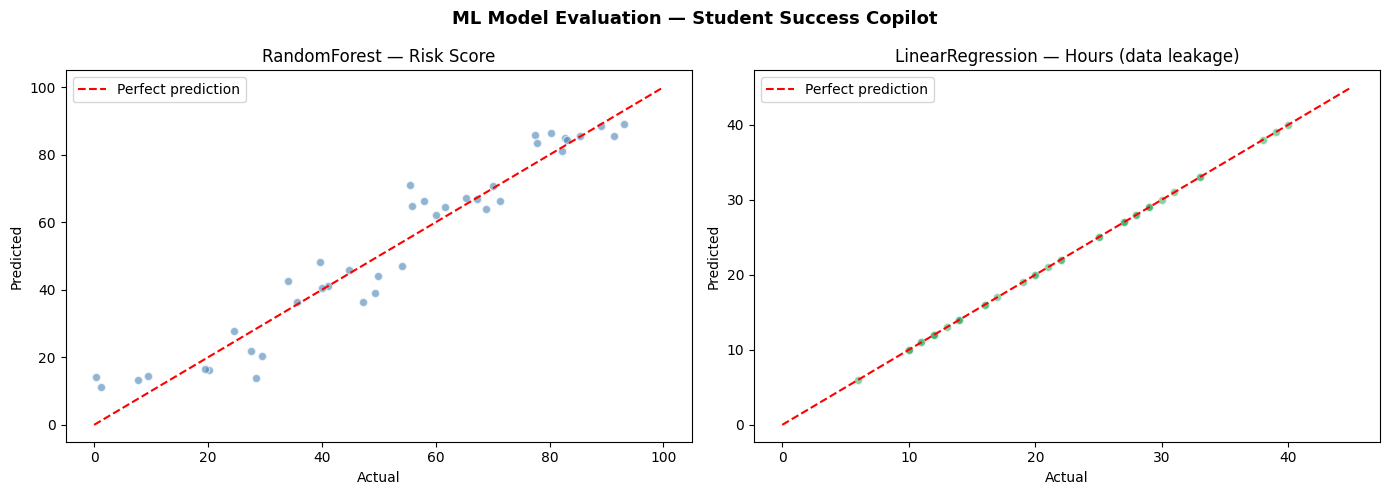

Plot saved as model_evaluation.png


In [65]:
# ── Cell 5: ML Training and Evaluation ──────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                              r2_score, accuracy_score, f1_score,
                              classification_report)

df = pd.read_csv('student_dataset.csv')

FEATURES = ['subjects', 'deadlines', 'days_to_deadline',
            'hours_needed', 'avail_hours', 'confidence',
            'stress', 'sleep', 'gender_code']

X       = df[FEATURES]
y_risk  = df['risk_score']
y_label = df['risk_label']
y_hours = df['hours_needed']

# 80/20 stratified split
X_train, X_test, yr_train, yr_test, yl_train, yl_test, yh_train, yh_test = \
    train_test_split(X, y_risk, y_label, y_hours,
                     test_size=0.2, random_state=42, stratify=y_label)

# Scale
scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train rows : {len(X_train)} | Test rows : {len(X_test)}")

# Train models
rf_risk  = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label = RandomForestClassifier(n_estimators=100, random_state=42)
lr_hours = LinearRegression()

rf_risk.fit(X_train_scaled,  yr_train)
rf_label.fit(X_train_scaled, yl_train)
lr_hours.fit(X_train_scaled, yh_train)

# Evaluate
risk_preds  = rf_risk.predict(X_test_scaled)
label_preds = rf_label.predict(X_test_scaled)
hour_preds  = lr_hours.predict(X_test_scaled)

print("\n=== RISK SCORE — RandomForestRegressor ===")
print(f"  MAE  : {mean_absolute_error(yr_test, risk_preds):.3f}")
print(f"  MSE  : {mean_squared_error(yr_test, risk_preds):.3f}")
print(f"  R²   : {r2_score(yr_test, risk_preds):.3f}")

print("\n=== RISK LABEL — RandomForestClassifier ===")
print(f"  Accuracy : {accuracy_score(yl_test, label_preds):.3f}")
print(f"  F1 Score : {f1_score(yl_test, label_preds, average='weighted'):.3f}")
print(f"\n{classification_report(yl_test, label_preds)}")

print("\n=== RECOMMENDED HOURS — LinearRegression ===")
print(f"  MAE  : {mean_absolute_error(yh_test, hour_preds):.3f}")
print(f"  R²   : {r2_score(yh_test, hour_preds):.3f}")
print(f"  ⚠ Note: R²=1.0 indicates data leakage — hours_needed is both feature and target")

# Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ML Model Evaluation — Student Success Copilot', fontsize=13, fontweight='bold')

axes[0].scatter(yr_test, risk_preds, alpha=0.6, color='steelblue', edgecolors='white')
axes[0].plot([0,100],[0,100], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_title('RandomForest — Risk Score')
axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted')
axes[0].legend()

axes[1].scatter(yh_test, hour_preds, alpha=0.6, color='mediumseagreen', edgecolors='white')
axes[1].plot([0,45],[0,45], 'r--', linewidth=1.5, label='Perfect prediction')
axes[1].set_title('LinearRegression — Hours (data leakage)')
axes[1].set_xlabel('Actual'); axes[1].set_ylabel('Predicted')
axes[1].legend()

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as model_evaluation.png")

In [66]:
# ── Cell 6: Rule Engine — Forward + Backward Chaining ───
from rules.rule_engine import forward_chain, backward_chain, get_followup_question

print("=" * 55)
print("  RULE ENGINE DEMONSTRATION")
print("=" * 55)

# Demo facts — Alex (struggling student)
alex_facts = {
    'subjects':          7,
    'deadlines':         4,
    'days_to_deadline':  2,
    'hours_needed':      30,
    'avail_hours':       2.0,
    'confidence':        20,
    'stress':            9,
    'sleep':             5.0,
    'gender':            'female',
    'risk_score':        85.4,
    'missed_sessions':   4,
    'total_sessions':    10
}

print("\n── Student: Alex (Struggling) ──")
print(f"   stress={alex_facts['stress']}, sleep={alex_facts['sleep']}h, "
      f"confidence={alex_facts['confidence']}%, "
      f"days_to_deadline={alex_facts['days_to_deadline']}")

print("\n=== FORWARD CHAINING ===\n")
fired = forward_chain(alex_facts)
for r in fired:
    print(f"  [{r['id']}] {r['label']} [conf: {r['confidence']}]")
    print(f"       → {r['action']}\n")
print(f"  Total rules fired: {len(fired)}")

print("\n=== BACKWARD CHAINING ===\n")
result = backward_chain(alex_facts)
print(f"  Goal: {result['goal']}\n")
for line in result['trace']:
    print(f"  {line}")

print("\n=== FOLLOW-UP QUESTION (driven by backward chaining) ===\n")
fq = get_followup_question(alex_facts)
print(f"  Triggered by : {fq['reason']}")
print(f"  Question     : {fq['question']}")

# Jordan — well prepared
print("\n\n── Student: Jordan (Well-Prepared) ──")
jordan_facts = {
    'subjects': 3, 'deadlines': 1, 'days_to_deadline': 6,
    'hours_needed': 10, 'avail_hours': 6.0, 'confidence': 85,
    'stress': 2, 'sleep': 8.0, 'gender': 'male',
    'risk_score': 13.7, 'missed_sessions': 0, 'total_sessions': 8
}
fired2 = forward_chain(jordan_facts)
print(f"\n=== FORWARD CHAINING — {len(fired2)} rule(s) fired ===\n")
for r in fired2:
    print(f"  [{r['id']}] {r['label']} [conf: {r['confidence']}]")
    print(f"       → {r['action']}\n")

  RULE ENGINE DEMONSTRATION

── Student: Alex (Struggling) ──
   stress=9, sleep=5.0h, confidence=20%, days_to_deadline=2

=== FORWARD CHAINING ===

  [R1] Imminent Deadline [conf: 0.95]
       → Deadline is within 2 days. Drop all non-urgent tasks and focus entirely on this.

  [R2] Deadline Within 3 Days [conf: 0.85]
       → Deadline approaching within 3 days. Set this as top priority immediately.

  [R3] Low Available Time [conf: 0.8]
       → Available study time is very low. Use 25-minute Pomodoro sessions to maximise focus.

  [R4] High Stress [conf: 0.8]
       → Stress level is high. Schedule a 30-minute break after every 2 hours of study.

  [R5] Sleep Deprivation [conf: 0.9]
       → Sleeping less than 6 hours severely reduces cognitive performance. Prioritise sleep tonight.

  [R6] Low Confidence [conf: 0.75]
       → Confidence is below 40%. Break tasks into smaller steps and track each small win.

  [R7] Heavy Subject Load [conf: 0.7]
       → Managing 6+ subjects. Create

In [67]:
# ── Cell 7: Search Planner — Greedy vs A* ───────────────
from planner.search_planner import build_tasks, greedy_planner, astar_planner

print("=" * 55)
print("  SEARCH PLANNER DEMONSTRATION")
print("=" * 55)

print("\n── Problem Formulation ──")
print("  State  : weekly schedule + remaining hours per subject")
print("  Actions: allocate up to 2.5h per subject per day")
print("  Goal   : all subjects scheduled before deadlines")

# Build tasks for Alex
tasks = build_tasks(
    num_subjects  = 7,
    num_deadlines = 4,
    hours_needed  = 30,
    subject_names = ['Mathematics','Computer Science','Physics',
                     'History','Economics','Chemistry','Literature']
)

print(f"\n── Tasks created: {len(tasks)} subjects ──")
for t in tasks:
    dl = f"deadline day {t['deadline_day']}" if t['deadline_day'] <= 7 else "no deadline"
    print(f"  {t['name']:<20} {t['hours']}h  |  {dl}")

greedy = greedy_planner(tasks, avail_hours_per_day=2.0)
astar  = astar_planner(tasks,  avail_hours_per_day=2.0)

print(f"\n── Strategy Comparison ──")
print(f"  {'Method':<22} {'Nodes':>6} {'Backtracks':>10} {'Time(ms)':>10}")
print(f"  {'-'*52}")
print(f"  {greedy['method']:<22} {greedy['nodes']:>6} "
      f"{greedy['backtracks']:>10} {greedy['time_ms']:>10}")
print(f"  {astar['method']:<22}  {astar['nodes']:>6} "
      f"{astar['backtracks']:>10}  {astar['time_ms']:>10}")
print(f"\n  → A* selected: fewer nodes + global estimate f(n)=g+h")

print(f"\n── A* Weekly Schedule ──")
for day, slots in astar['schedule'].items():
    if slots:
        items = ', '.join(f"{s['task']} {s['hours']}h" for s in slots)
        print(f"  {day:<12}: {items}")
    else:
        print(f"  {day:<12}: Rest / buffer day")

  SEARCH PLANNER DEMONSTRATION

── Problem Formulation ──
  State  : weekly schedule + remaining hours per subject
  Actions: allocate up to 2.5h per subject per day
  Goal   : all subjects scheduled before deadlines

── Tasks created: 7 subjects ──
  Mathematics          5.1h  |  deadline day 1
  Computer Science     5.1h  |  deadline day 2
  Physics              5.1h  |  deadline day 3
  History              5.1h  |  deadline day 4
  Economics            3.4h  |  no deadline
  Chemistry            3.4h  |  no deadline
  Literature           3.4h  |  no deadline

── Strategy Comparison ──
  Method                  Nodes Backtracks   Time(ms)
  ----------------------------------------------------
  Greedy Best-First           9          7       0.07
  A* Heuristic                 7          7       0.046

  → A* selected: fewer nodes + global estimate f(n)=g+h

── A* Weekly Schedule ──
  Monday      : Mathematics 2.0h
  Tuesday     : Mathematics 2.0h
  Wednesday   : Mathematics 1.1h, C

In [68]:
# ── Cell 8: Fuzzy Logic Controller ──────────────────────
from fuzzy.fuzzy_logic import fuzzy_controller

print("=" * 55)
print("  FUZZY LOGIC CONTROLLER DEMONSTRATION")
print("=" * 55)

test_cases = [
    {'name': 'Alex (Struggling)',      'stress': 9, 'avail': 2.0, 'conf': 20},
    {'name': 'Jordan (Well-Prepared)', 'stress': 2, 'avail': 6.0, 'conf': 85},
    {'name': 'Sam (Borderline)',       'stress': 5, 'avail': 4.0, 'conf': 55},
]

for tc in test_cases:
    result = fuzzy_controller(tc['stress'], tc['avail'], tc['conf'])
    print(f"\n  Student  : {tc['name']}")
    print(f"  Inputs   : stress={tc['stress']}, avail={tc['avail']}h, conf={tc['conf']}%")
    print(f"  Score    : {result['intensity_score']}/100")
    print(f"  Intensity: {result['intensity_label']}")
    print(f"  Advice   : {result['adjustment']}")
    print(f"  Memberships:")
    for key, sets in result['memberships'].items():
        vals = "  |  ".join(f"{k}={v:.2f}" for k, v in sets.items())
        print(f"    {key:<12}: {vals}")

  FUZZY LOGIC CONTROLLER DEMONSTRATION

  Student  : Alex (Struggling)
  Inputs   : stress=9, avail=2.0h, conf=20%
  Score    : 91.7/100
  Intensity: CRITICAL
  Advice   : 🔴 Maximum effort needed. Study every available hour this week.
  Memberships:
    stress      : LOW=0.00  |  MEDIUM=0.00  |  HIGH=1.00
    workload    : HEAVY=1.00  |  MODERATE=0.00  |  LIGHT=0.00
    confidence  : LOW=1.00  |  MEDIUM=0.00  |  HIGH=0.00

  Student  : Jordan (Well-Prepared)
  Inputs   : stress=2, avail=6.0h, conf=85%
  Score    : 25.0/100
  Intensity: LIGHT
  Advice   : 🟢 Light intensity. Stay consistent but avoid overworking.
  Memberships:
    stress      : LOW=1.00  |  MEDIUM=0.00  |  HIGH=0.00
    workload    : HEAVY=0.00  |  MODERATE=0.25  |  LIGHT=0.67
    confidence  : LOW=0.00  |  MEDIUM=0.00  |  HIGH=1.00

  Student  : Sam (Borderline)
  Inputs   : stress=5, avail=4.0h, conf=55%
  Score    : 50.0/100
  Intensity: MODERATE
  Advice   : 🟡 Moderate intensity. Maintain steady progress with planne

In [69]:
# ── Cell 9: Full System Demo — Two Scenarios ────────────
from ml.ml_model import predict
from rules.rule_engine import forward_chain, backward_chain
from planner.search_planner import build_tasks, greedy_planner, astar_planner
from fuzzy.fuzzy_logic import fuzzy_controller

def run_scenario(scenario):
    print("=" * 60)
    print(f"  DEMO SCENARIO: {scenario['name'].upper()}")
    print("=" * 60)

    # ML Prediction
    ml = predict(
        subjects         = scenario['subjects'],
        deadlines        = scenario['deadlines'],
        days_to_deadline = scenario['days_to_deadline'],
        hours_needed     = scenario['hours_needed'],
        avail_hours      = scenario['avail_hours'],
        confidence       = scenario['confidence'],
        stress           = scenario['stress'],
        sleep            = scenario['sleep'],
        gender           = scenario['gender']
    )

    icons = {'LOW':'🟢','MODERATE':'🟡','HIGH':'🟠','CRITICAL':'🔴'}
    print(f"\n  {icons.get(ml['risk_label'],'⚪')} RISK  : {ml['risk_label']} ({ml['risk_score']}/100)")
    print(f"  📚 HOURS : {ml['rec_hours']}h recommended this week")

    # Fuzzy
    fz = fuzzy_controller(scenario['stress'],
                          scenario['avail_hours'],
                          scenario['confidence'])
    print(f"  🌀 FUZZY : {fz['intensity_label']} ({fz['intensity_score']}/100) — {fz['adjustment']}")

    # Rules
    facts = {**scenario, 'risk_score': ml['risk_score']}
    fired = forward_chain(facts)
    bwd   = backward_chain(facts)
    print(f"\n  RULE ENGINE — {len(fired)} rule(s) fired")
    for r in fired[:5]:
        print(f"    [{r['id']}] {r['label']} (conf:{r['confidence']}) → {r['action']}")
    if len(fired) > 5:
        print(f"    ... and {len(fired)-5} more rules")

    print(f"\n  BACKWARD CHAINING — Goal: {bwd['goal']}")
    for t in bwd['trace']:
        print(f"    {t}")

    # Schedule
    tasks = build_tasks(scenario['subjects'], scenario['deadlines'],
                        scenario['hours_needed'], scenario['subject_names'])
    astar = astar_planner(tasks, scenario['avail_hours'])
    greedy = greedy_planner(tasks, scenario['avail_hours'])

    print(f"\n  SEARCH COMPARISON")
    print(f"    {'Method':<22} {'Nodes':>6} {'Time(ms)':>10}")
    print(f"    {greedy['method']:<22} {greedy['nodes']:>6} {greedy['time_ms']:>10}")
    print(f"    {astar['method']:<22}  {astar['nodes']:>6}  {astar['time_ms']:>10}")

    print(f"\n  WEEKLY PLAN (A*)")
    for day, slots in astar['schedule'].items():
        if slots:
            items = ', '.join(f"{s['task']} {s['hours']}h" for s in slots)
            print(f"    {day:<12}: {items}")
        else:
            print(f"    {day:<12}: Rest")
    print()

# ── Scenario 1: Alex ──
run_scenario({
    'name': 'Alex — Struggling Student',
    'gender': 'female', 'subjects': 7,
    'subject_names': ['Mathematics','Computer Science','Physics',
                      'History','Economics','Chemistry','Literature'],
    'deadlines': 4, 'days_to_deadline': 2,
    'hours_needed': 30, 'avail_hours': 2.0,
    'confidence': 20, 'stress': 9, 'sleep': 5.0,
    'missed_sessions': 4, 'total_sessions': 10
})

# ── Scenario 2: Jordan ──
run_scenario({
    'name': 'Jordan — Well-Prepared Student',
    'gender': 'male', 'subjects': 3,
    'subject_names': ['Biology', 'Statistics', 'Psychology'],
    'deadlines': 1, 'days_to_deadline': 6,
    'hours_needed': 10, 'avail_hours': 6.0,
    'confidence': 85, 'stress': 2, 'sleep': 8.0,
    'missed_sessions': 0, 'total_sessions': 8
})

# ── Scenario 3: Borderline Student ──
run_scenario({
    'name': 'Sam — Borderline Student',
    'gender': 'non-binary', 'subjects': 5,
    'subject_names': ['Economics', 'Statistics',
                      'Literature', 'Chemistry', 'Psychology'],
    'deadlines': 2, 'days_to_deadline': 4,
    'hours_needed': 18, 'avail_hours': 4.0,
    'confidence': 55, 'stress': 5, 'sleep': 6.5,
    'missed_sessions': 1, 'total_sessions': 8
})

  DEMO SCENARIO: ALEX — STRUGGLING STUDENT

  🔴 RISK  : CRITICAL (87.0/100)
  📚 HOURS : 30.0h recommended this week
  🌀 FUZZY : CRITICAL (91.7/100) — 🔴 Maximum effort needed. Study every available hour this week.

  RULE ENGINE — 12 rule(s) fired
    [R1] Imminent Deadline (conf:0.95) → Deadline is within 2 days. Drop all non-urgent tasks and focus entirely on this.
    [R2] Deadline Within 3 Days (conf:0.85) → Deadline approaching within 3 days. Set this as top priority immediately.
    [R3] Low Available Time (conf:0.8) → Available study time is very low. Use 25-minute Pomodoro sessions to maximise focus.
    [R4] High Stress (conf:0.8) → Stress level is high. Schedule a 30-minute break after every 2 hours of study.
    [R5] Sleep Deprivation (conf:0.9) → Sleeping less than 6 hours severely reduces cognitive performance. Prioritise sleep tonight.
    ... and 7 more rules

  BACKWARD CHAINING — Goal: Reduce student risk level
    [R12] High Risk — Root Cause Analysis (confidence 0.9) 

In [70]:
# ── Cell 10: Limitations and Discussion ─────────────────
print("=" * 55)
print("  ML MODEL LIMITATIONS")
print("=" * 55)
print("""
  1. Synthetic dataset (200 rows)
     Real student data would produce different accuracy.
     97.5% classification accuracy reflects clean profile
     separation in synthetic data — not real-world complexity.

  2. Data leakage in hours model
     hours_needed is both an input feature AND the prediction
     target for LinearRegression. R²=1.0 is not genuine.
     A corrected version would use a separately derived target.

  3. Gender encoding simplification
     Encoding as 0.0/0.5/1.0 implies an ordinal relationship
     between gender categories that does not exist in reality.
     One-hot encoding would be more appropriate.

  4. No cross-validation
     RandomForest may overfit on 160 training rows without
     k-fold cross-validation. Single train/test split is
     a simplification for demonstration purposes.

  5. No real-world validation
     The system has not been tested with actual students.
     All outputs are recommendations only.
""")

  ML MODEL LIMITATIONS

  1. Synthetic dataset (200 rows)
     Real student data would produce different accuracy.
     97.5% classification accuracy reflects clean profile
     separation in synthetic data — not real-world complexity.

  2. Data leakage in hours model
     hours_needed is both an input feature AND the prediction
     target for LinearRegression. R²=1.0 is not genuine.
     A corrected version would use a separately derived target.

  3. Gender encoding simplification
     Encoding as 0.0/0.5/1.0 implies an ordinal relationship
     between gender categories that does not exist in reality.
     One-hot encoding would be more appropriate.

  4. No cross-validation
     RandomForest may overfit on 160 training rows without
     k-fold cross-validation. Single train/test split is
     a simplification for demonstration purposes.

  5. No real-world validation
     The system has not been tested with actual students.
     All outputs are recommendations only.



In [71]:
# ── Cell 11: Note on Interactive Mode ───────────────────
print("""
NOTE FOR EXAMINER:
==================
The full interactive terminal UI is in ui/app.py
and runs via main.py in PyCharm.

To run the interactive version locally:
  1. Open PyCharm
  2. Run main.py
  3. Choose option 1 to enter details manually
     or option 2/3 for demo scenarios

The Colab notebook above demonstrates all four
AI components with pre-defined scenarios.
Both environments use identical code — the same
planner/, rules/, ml/, and fuzzy/ modules.
""")


NOTE FOR EXAMINER:
The full interactive terminal UI is in ui/app.py
and runs via main.py in PyCharm.

To run the interactive version locally:
  1. Open PyCharm
  2. Run main.py
  3. Choose option 1 to enter details manually
     or option 2/3 for demo scenarios

The Colab notebook above demonstrates all four
AI components with pre-defined scenarios.
Both environments use identical code — the same
planner/, rules/, ml/, and fuzzy/ modules.

